In [1]:
import matplotlib.pyplot as plt 
import pandas as pd
from stimuli_effect_identification import dataset_simulation

/home/baubouin/Code/stimuli_effect_identification/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data_measure = pd.read_csv('data/database.csv')


In [3]:
data_measure.rename(columns={'opstart': 'surgery_time'}, inplace=True)
data_measure.intubation_time = (data_measure.intubation_time - 2*60).clip(0, 6000) # from end to start of intubation
data_measure['Propofol'] = data_measure['Propofol']*20/3600
data_measure['Remifentanil'] = data_measure['Remifentanil']*20/3600
data_measure['TPR'] = (data_measure['MAP'] / (data_measure['HR'] * data_measure['SV'])).clip(0, 0.04)
data_measure = data_measure.query('split == "test"').reset_index()
# data_measure = data_measure.query('caseid < 600')

In [4]:
data_simu_stimuli = pd.read_csv('data/simulated_vitaldb_test.csv')
data_simu_no_stimuli = pd.read_csv('data/simulated_vitaldb_no_stimuli.csv')
data_simu_no_stimuli_recalibration = pd.read_csv('data/simulated_vitaldb_test_recalibration.csv')

In [5]:
data_simu_stimuli = pd.merge(data_simu_stimuli, data_measure[['caseid', 'Time', 'surgery_time', 'intubation_time']], on=['caseid', 'Time'])
data_simu_no_stimuli_recalibration = pd.merge(data_simu_no_stimuli_recalibration, data_measure[['caseid', 'Time', 'surgery_time', 'intubation_time']], on=['caseid', 'Time'])
data_simu_no_stimuli = pd.merge(data_simu_no_stimuli, data_measure[['caseid', 'Time', 'surgery_time', 'intubation_time']], on=['caseid', 'Time'])

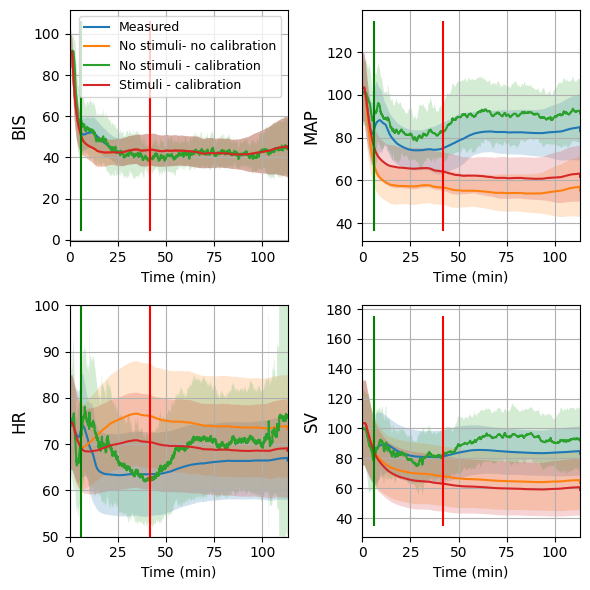

In [13]:
signal_list = ['BIS', 'MAP', 'HR', 'SV']
median_intub_time = data_simu_stimuli['intubation_time'].median()/60
median_surg_time = data_simu_stimuli['surgery_time'].median()/60

zoom = 'all' #surgery, intub, all

for df in [data_simu_stimuli, data_simu_no_stimuli, data_measure, data_simu_no_stimuli_recalibration]:
    if zoom=='all':
        df['Time_aligned'] = df['Time']
    if zoom=='intub':
        df['Time_aligned'] = df['Time'] - df['intubation_time']
    if zoom=='surgery':
        df['Time_aligned'] = df['Time'] - df['surgery_time']

end_time_min = data_measure.groupby('caseid').Time.max().min()

plt.figure(figsize=(6,6))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    legend = [
        'Measured',
        'No stimuli- no calibration',
        'No stimuli - calibration',
        'Stimuli - calibration',
    ]
    for j,df in enumerate([data_simu_stimuli, data_simu_no_stimuli, data_measure, data_simu_no_stimuli_recalibration]):
        mean = df.groupby("Time_aligned")[signal].mean().reset_index()
        std = df.groupby("Time_aligned")[signal].std().reset_index()
        x = mean['Time_aligned'].values/60
        plt.plot(x, mean[f"{signal}"].values, label=legend[j])
        plt.fill_between(x, mean[f"{signal}"].values-std[f"{signal}"].values, mean[f"{signal}"].values+std[f"{signal}"].values
        , alpha = 0.2)
    if i==0:
        plt.legend()
    y_lim = plt.gca().get_ylim()
    if zoom == 'all':
        plt.vlines(median_intub_time,y_lim[0], y_lim[1], 'g')
        plt.vlines(median_surg_time,y_lim[0], y_lim[1], 'r')
    if zoom=='intub':
        plt.vlines(0,y_lim[0], y_lim[1], 'g')
    if zoom=='surgery':
        plt.vlines(0,y_lim[0], y_lim[1], 'r')
    plt.grid()
    plt.ylabel(signal, fontsize=12)
    if signal=='HR':
        plt.ylim(50,100)
    if i==0:
        plt.legend(fontsize=9)
    plt.xlabel('Time (min)')
    if zoom == 'all':
        plt.xlim([0,end_time_min/60])
    if zoom == 'intub':
        plt.xlim([-5, 20])
    if zoom == 'surgery':
        plt.xlim([-10, 20])
plt.tight_layout()
plt.savefig(f'output/dist_{zoom}.pdf', dpi=300)
plt.show()

In [20]:
from example.performance_computation import compute_kpis_with_std

# Labels for each row
labels = [
    "No stimuli - no calibration",
    "No stimuli - calibration",
    "Stimuli - calibration"
]



for signal in signal_list:
    res_no_stimuli = compute_kpis_with_std(data_measure, data_simu_no_stimuli, value_col=signal)
    res_stimuli = compute_kpis_with_std(data_measure, data_simu_stimuli, value_col=signal)
    res_calibration = compute_kpis_with_std(data_measure, data_simu_no_stimuli_recalibration, value_col=signal)
    print(f'{signal}:')
    # Generate LaTeX table rows
    latex_rows = []
    df = pd.concat([res_no_stimuli, res_calibration, res_stimuli], ignore_index=True)
    for i, row in df.iterrows():

        mdape = f"${row['MDAPE_mean']:.1f} \\pm {row['MDAPE_std']:.1f}$"
        mae = f"${row['MAE_mean']:.1f} \\pm {row['MAE_std']:.1f}$"
        rmse = f"${row['RMSE_mean']:.1f} \\pm {row['RMSE_std']:.1f}$"
        mdpe = f"${row['MDPE_mean']:.1f} \\pm {row['MDPE_std']:.1f}$"
        r2 = f"${row['corr_mean']:.2f} \\pm {row['corr_std']:.2f}$"

        label = labels[i]

        if i == 0:
            first_column = fr"\multirow{{3}}{{*}}{{{signal}}}"
        else:
            first_column = ""

        latex_row = (
            f"{first_column} & {label} & "
            f"{mdpe} & {mdape} & {mae} & {rmse} & {r2} \\\\"
        )
        latex_rows.append(latex_row)

    # Print final LaTeX code
    print("\n".join(latex_rows))

/home/baubouin/Code/stimuli_effect_identification/example/performance_computation.py:45: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
/home/baubouin/Code/stimuli_effect_identification/example/performance_computation.py:45: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
/home/baubouin/Code/stimuli_effect_ident

BIS:
0
1
2
\multirow{3}{*}{BIS} & No stimuli - no calibration & $2.5 \pm 18.7$ & $18.1 \pm 9.1$ & $8.9 \pm 3.0$ & $10.7 \pm 3.1$ & $0.81 \pm 0.08$ \\
 & No stimuli - calibration & $2.5 \pm 18.7$ & $18.1 \pm 9.1$ & $8.9 \pm 3.0$ & $10.7 \pm 3.1$ & $0.81 \pm 0.08$ \\
 & Stimuli - calibration & $3.1 \pm 18.7$ & $17.9 \pm 9.3$ & $8.8 \pm 3.0$ & $10.6 \pm 3.1$ & $0.82 \pm 0.07$ \\


/home/baubouin/Code/stimuli_effect_identification/example/performance_computation.py:45: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
/home/baubouin/Code/stimuli_effect_identification/example/performance_computation.py:45: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
/home/baubouin/Code/stimuli_effect_ident

MAP:
0
1
2
\multirow{3}{*}{MAP} & No stimuli - no calibration & $-36.9 \pm 9.7$ & $36.9 \pm 9.7$ & $32.6 \pm 9.4$ & $34.8 \pm 9.4$ & $0.32 \pm 0.24$ \\
 & No stimuli - calibration & $-29.2 \pm 10.8$ & $29.4 \pm 10.4$ & $26.3 \pm 9.6$ & $28.8 \pm 9.6$ & $0.27 \pm 0.27$ \\
 & Stimuli - calibration & $-7.0 \pm 12.5$ & $14.0 \pm 6.1$ & $13.7 \pm 5.5$ & $16.4 \pm 5.6$ & $0.40 \pm 0.22$ \\


/home/baubouin/Code/stimuli_effect_identification/example/performance_computation.py:45: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
/home/baubouin/Code/stimuli_effect_identification/example/performance_computation.py:45: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
/home/baubouin/Code/stimuli_effect_ident

HR:
0
1
2
\multirow{3}{*}{HR} & No stimuli - no calibration & $7.4 \pm 21.2$ & $19.1 \pm 13.6$ & $14.0 \pm 7.8$ & $17.1 \pm 8.2$ & $0.01 \pm 0.27$ \\
 & No stimuli - calibration & $0.3 \pm 19.5$ & $17.8 \pm 10.1$ & $13.5 \pm 6.7$ & $16.8 \pm 7.4$ & $0.13 \pm 0.27$ \\
 & Stimuli - calibration & $-4.0 \pm 16.5$ & $15.7 \pm 8.1$ & $12.8 \pm 6.0$ & $16.5 \pm 6.9$ & $0.27 \pm 0.23$ \\
SV:
0
1
2
\multirow{3}{*}{SV} & No stimuli - no calibration & $-23.2 \pm 24.1$ & $29.7 \pm 17.0$ & $27.0 \pm 14.2$ & $30.8 \pm 13.8$ & $0.04 \pm 0.36$ \\
 & No stimuli - calibration & $-28.8 \pm 22.7$ & $32.9 \pm 16.9$ & $29.7 \pm 14.4$ & $33.4 \pm 14.2$ & $0.05 \pm 0.36$ \\
 & Stimuli - calibration & $-2.0 \pm 22.5$ & $20.9 \pm 11.5$ & $19.2 \pm 8.8$ & $22.6 \pm 8.7$ & $0.25 \pm 0.34$ \\


/home/baubouin/Code/stimuli_effect_identification/example/performance_computation.py:45: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  patient_kpis = df.groupby(case_col).apply(per_patient)
